# TAHAP 3 - LABELLING OTOMATIS

Peta instans hasil segmentasi (tahap 2) diubah menjadi label YOLO:

| Keluaran | Format | Dipakai untuk |
|---|---|---|
| `labels_seg/<nama>.txt` | `class_id x1 y1 x2 y2 ...` (polygon) | `yolo26n-seg` |
| `labels_det/<nama>.txt` | `class_id cx cy w h` (kotak) | `yolo26n` |
| `images/<nama>.jpg` | gambar bersih asli (bukan citra kontras) | citra latih |
| `gambar_berlabel/` | gambar + polygon + kotak | pemeriksaan visual |

Semua koordinat dinormalisasi 0-1.

Hanya gambar berstatus **`ok` / `roi_manual`** yang dilabel, karena label dari mask yang salah merusak pelatihan. Gambar `perlu_cek` dapat diperbaiki lewat notebook 02b lalu 02 diulang, atau dipaksa ikut dengan `SERTAKAN_PERLU_CEK = True`.

Letakkan notebook ini di `notebooks/`; modul pendukung ada di `scripts/`.

## 1. Setup dan import

In [1]:
import sys, os
from pathlib import Path

SCRIPTS = Path.cwd().resolve().parent / "scripts"
if not SCRIPTS.is_dir():
    SCRIPTS = Path.cwd().resolve()
sys.path.insert(0, str(SCRIPTS))

# Opsional: bila folder proyek bukan induk dari scripts/, hilangkan tanda # dan isi path-nya
# os.environ["PROYEK_ROOT"] = r"D:\rompi-cerdas-fin"

import cv2
import numpy as np
from IPython.display import Image, display

from config import CLASSES, D_CLEAN, D_LABEL, D_SEG, ROOT
from seg_profil import PROFIL
from util import baca_csv, baca_gambar, bersihkan, log, simpan_gambar, tabel, tulis_csv
from yolo_util import baca_label_seg, gambar_berlabel, instans_ke_polygon, tulis_label

TAHAP = "03_labelling"
print("Folder proyek :", ROOT)
print("Laporan segmentasi:", D_SEG / "laporan_segmentasi.csv", "| ada:", (D_SEG / "laporan_segmentasi.csv").exists())
print("Folder hasil  :", D_LABEL)
print("ID kelas YOLO :", {i: k for i, k in enumerate(CLASSES)})

Folder proyek : C:\Projek\vestcare-dataset
Laporan segmentasi: C:\Projek\vestcare-dataset\hasil\02_segmentasi\laporan_segmentasi.csv | ada: True
Folder hasil  : C:\Projek\vestcare-dataset\hasil\03_labelling
ID kelas YOLO : {0: 'pohon', 1: 'lubang', 2: 'orang', 3: 'motor', 4: 'mobil'}


## 2. Parameter

Setara argumen CLI `--sertakan-perlu-cek`.

In [2]:
SERTAKAN_PERLU_CEK = False   # True = ikutkan gambar berstatus perlu_cek / cadangan_roi

layak = {"ok", "roi_manual"} | ({"perlu_cek", "cadangan_roi"} if SERTAKAN_PERLU_CEK else set())
print("Status yang dilabel:", sorted(layak))

Status yang dilabel: ['ok', 'roi_manual']


## 3. Fungsi bantu tampilan

In [3]:
def tampil(img, maks=1100):
    h, w = img.shape[:2]
    s = min(1.0, maks / max(h, w))
    if s < 1.0:
        img = cv2.resize(img, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)
    display(Image(data=cv2.imencode(".png", img)[1].tobytes()))


def tampil_baris(daftar, tinggi=190, per_baris=4):
    """daftar = [(citra BGR, teks)]"""
    for i in range(0, len(daftar), per_baris):
        ubin = []
        for im, teks in daftar[i:i + per_baris]:
            s = tinggi / im.shape[0]
            t = cv2.resize(im, (max(1, int(im.shape[1] * s)), tinggi), interpolation=cv2.INTER_AREA)
            cv2.putText(t, teks, (4, 14), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (0, 0, 0), 3, cv2.LINE_AA)
            cv2.putText(t, teks, (4, 14), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 255), 1, cv2.LINE_AA)
            ubin.append(t)
        tampil(np.hstack(ubin))

print("fungsi siap")

fungsi siap


## 4. Baca laporan segmentasi dan hitung ulang status

Status **dihitung ulang dari skor** dengan `ambang_cek` di `seg_profil.py`, sehingga ambang bisa disetel tanpa mengulang segmentasi. Gambar `roi_manual` selalu dianggap layak.

In [4]:
laporan = baca_csv(D_SEG / "laporan_segmentasi.csv")
if not laporan:
    raise SystemExit("laporan_segmentasi.csv tidak ada: jalankan notebook 02_segmentasi dulu")

for r in laporan:
    kelas = r["kelas"]
    if r["status"] == "roi_manual":
        status = "roi_manual"
    elif r["status"] == "cadangan_roi" or float(r["skor"]) < PROFIL[kelas]["ambang_cek"]:
        status = "perlu_cek" if r["status"] != "cadangan_roi" else "cadangan_roi"
    else:
        status = "ok"
    r["status"] = status

print(f"{'kelas':8s} {'ambang':>7s} {'total':>6s} {'ok':>5s} {'roi_manual':>11s} {'perlu_cek':>10s} {'cadangan':>9s} {'dilabel':>8s}")
for k in CLASSES:
    rr = [x for x in laporan if x["kelas"] == k]
    if rr:
        c = lambda s: sum(x["status"] == s for x in rr)
        print(f"{k:8s} {PROFIL[k]['ambang_cek']:7.2f} {len(rr):6d} {c('ok'):5d} {c('roi_manual'):11d} {c('perlu_cek'):10d} "
              f"{c('cadangan_roi'):9d} {sum(x['status'] in layak for x in rr):8d}")

kelas     ambang  total    ok  roi_manual  perlu_cek  cadangan  dilabel
pohon       0.85    187   123          64          0         0      187
lubang      0.80    317   131         186          0         0      317
orang       0.84    123    53          70          0         0      123
motor       0.88    220    24         196          0         0      220
mobil       0.95    200    46         154          0         0      200


## 5. Demo konversi pada satu gambar

Mask peta instans -> polygon (Douglas-Peucker, objek < 100 px dibuang) -> baris label seg dan det. Panel: **mask | gambar berlabel**.

File        : pohon_primer-pohon-1.jpg (pohon, id 0)
Ukuran      : 312 x 416
Objek di mask: 1 | polygon lolos min 100 px: 1

objek 1: 43 titik polygon
  seg: 0 0.237179 0.000000 0.195513 0.036058 0.092949 0.069712 0.076923 0.139423 0.137821 0.276442 0.089744 0.408654  ...
  det: 0 0.397436 0.498798 0.653846 0.997596


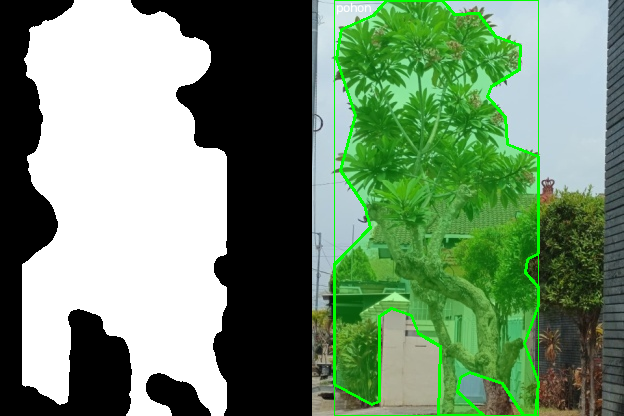

In [5]:
contoh = next((r for r in laporan if r["status"] in layak), None)
if contoh is None:
    print("Belum ada gambar layak untuk didemokan.")
else:
    kelas, nama = contoh["kelas"], contoh["file"]
    stem = nama.rsplit(".", 1)[0]
    lab = cv2.imdecode(np.fromfile(str(D_SEG / "mask" / kelas / f"{stem}.png"), "uint8"), cv2.IMREAD_UNCHANGED)
    img = baca_gambar(D_CLEAN / "bersih" / kelas / nama)
    h, w = img.shape[:2]
    polys = instans_ke_polygon(lab)
    print("File        :", nama, f"({kelas}, id {CLASSES.index(kelas)})")
    print("Ukuran      :", w, "x", h)
    print("Objek di mask:", int(lab.max()), "| polygon lolos min 100 px:", len(polys))
    from yolo_util import baris_seg, baris_det
    for i, p in polys:
        print(f"\nobjek {i}: {len(p)} titik polygon")
        print("  seg:", baris_seg(CLASSES.index(kelas), p, w, h)[:110], "...")
        print("  det:", baris_det(CLASSES.index(kelas), p, w, h))
    if polys:
        mask_vis = cv2.cvtColor((lab > 0).astype(np.uint8) * 255, cv2.COLOR_GRAY2BGR)
        tampil(np.hstack([mask_vis, gambar_berlabel(img, polys, kelas)]))

## 6. Proses labelling seluruh gambar

> Sel ini **menghapus dan membuat ulang** `hasil/03_labelling/`.

In [6]:
bersihkan(D_LABEL)
hasil, ring = [], {k: {"gambar": 0, "dilewati": 0, "objek": 0} for k in CLASSES}
alasan_lewat = {"status_tidak_layak": 0, "tanpa_polygon": 0}

for r in laporan:
    kelas, nama = r["kelas"], r["file"]
    stem = nama.rsplit(".", 1)[0]
    if r["status"] not in layak:
        ring[kelas]["dilewati"] += 1
        alasan_lewat["status_tidak_layak"] += 1
        continue
    lab = cv2.imdecode(np.fromfile(str(D_SEG / "mask" / kelas / f"{stem}.png"), "uint8"), cv2.IMREAD_UNCHANGED)
    img = baca_gambar(D_CLEAN / "bersih" / kelas / nama)
    h, w = img.shape[:2]
    polys = instans_ke_polygon(lab)
    if not polys:
        ring[kelas]["dilewati"] += 1
        alasan_lewat["tanpa_polygon"] += 1
        continue
    tulis_label(D_LABEL / "labels_seg" / f"{stem}.txt", D_LABEL / "labels_det" / f"{stem}.txt",
                CLASSES.index(kelas), polys, w, h)
    simpan_gambar(D_LABEL / "images" / nama, img, 95)
    simpan_gambar(D_LABEL / "gambar_berlabel" / nama, gambar_berlabel(img, polys, kelas), 90)
    ring[kelas]["gambar"] += 1
    ring[kelas]["objek"] += len(polys)
    hasil.append({"file": nama, "kelas": kelas, "n_objek": len(polys), "status_segmentasi": r["status"],
                  "skor": r["skor"], "lebar": w, "tinggi": h})

print("Dilewati:", alasan_lewat)
print("Gambar berlabel:", len(hasil))

Dilewati: {'status_tidak_layak': 0, 'tanpa_polygon': 1}
Gambar berlabel: 1046


## 7. Simpan laporan dan ringkasan

In [7]:
tulis_csv(D_LABEL / "laporan_labelling.csv", hasil,
          ["file", "kelas", "n_objek", "status_segmentasi", "skor", "lebar", "tinggi"])

baris = [{"kelas": k, **v} for k, v in ring.items()]
baris.append({"kelas": "TOTAL", **{c: sum(v[c] for v in ring.values()) for c in ("gambar", "objek", "dilewati")}})
tabel("Ringkasan labelling", baris, ["kelas", "gambar", "objek", "dilewati"])
log(TAHAP, f"laporan -> {D_LABEL / 'laporan_labelling.csv'}")


Ringkasan labelling
kelas   gambar  objek  dilewati
pohon   187     187    0       
lubang  317     536    0       
orang   123     173    0       
motor   220     291    0       
mobil   199     221    1       
TOTAL   1046    1408   1       
[03_labelling] laporan -> C:\Projek\vestcare-dataset\hasil\03_labelling\laporan_labelling.csv


## 8. Distribusi objek per gambar

Berapa banyak gambar punya 1, 2, 3, ... objek, per kelas. Penting untuk tahap 4 (pengayaan) dan tahap 6 (split).

In [8]:
maks_n = max([r["n_objek"] for r in hasil], default=0)
print(f"{'kelas':8s} " + " ".join(f"{n:>4d}obj" for n in range(1, maks_n + 1)))
for k in CLASSES:
    rr = [r["n_objek"] for r in hasil if r["kelas"] == k]
    if rr:
        print(f"{k:8s} " + " ".join(f"{sum(x == n for x in rr):7d}" for n in range(1, maks_n + 1)))

kelas       1obj    2obj    3obj    4obj    5obj    6obj
pohon        187       0       0       0       0       0
lubang       204      59      28      10       6      10
orang         89      24       5       4       1       0
motor        160      51       7       2       0       0
mobil        182      14       2       0       1       0


## 9. Pemeriksaan format label

Memastikan setiap file label valid sebelum dipakai tahap 4-6:
- ID kelas sesuai kelas gambar
- koordinat polygon ada di rentang 0-1 dan minimal 3 titik
- jumlah baris `labels_seg` sama dengan `labels_det`
- kotak `labels_det` punya lebar/tinggi > 0

In [9]:
masalah = []
for r in hasil:
    stem = r["file"].rsplit(".", 1)[0]
    kid = CLASSES.index(r["kelas"])
    seg = (D_LABEL / "labels_seg" / f"{stem}.txt").read_text().split("\n")
    det = (D_LABEL / "labels_det" / f"{stem}.txt").read_text().split("\n")
    seg, det = [s for s in seg if s.strip()], [d for d in det if d.strip()]
    if len(seg) != len(det):
        masalah.append((r["file"], "jumlah baris seg != det"))
    for s in seg:
        t = s.split()
        v = np.array(t[1:], float)
        if int(t[0]) != kid:
            masalah.append((r["file"], "id kelas salah"))
        if len(v) < 6 or len(v) % 2:
            masalah.append((r["file"], "polygon < 3 titik / ganjil"))
        if v.min() < 0 or v.max() > 1:
            masalah.append((r["file"], "koordinat di luar 0-1"))
    for d in det:
        t = d.split()
        if float(t[3]) <= 0 or float(t[4]) <= 0:
            masalah.append((r["file"], "kotak berukuran 0"))
print(f"Diperiksa: {len(hasil)} file label")
print("Masalah   :", len(masalah))
for m in masalah[:20]:
    print("  ", m)
if not masalah:
    print("Semua label valid.")

Diperiksa: 1046 file label
Masalah   : 0
Semua label valid.


## 10. Galeri gambar berlabel

Polygon berwarna dengan kotak pembatas. Periksa dengan mata apakah labelnya pas.


== pohon: 187 gambar berlabel, tampil 8 ==


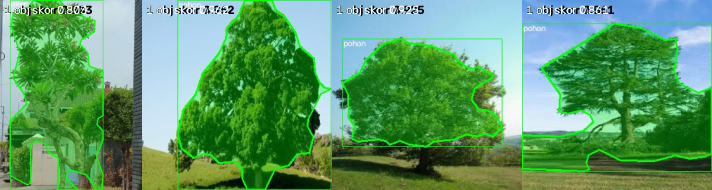

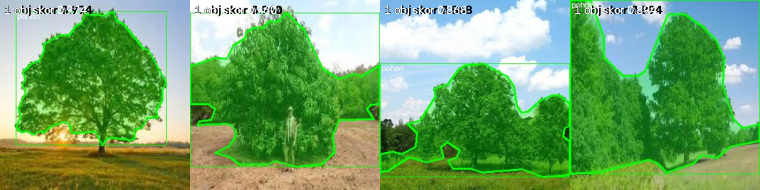


== lubang: 317 gambar berlabel, tampil 8 ==


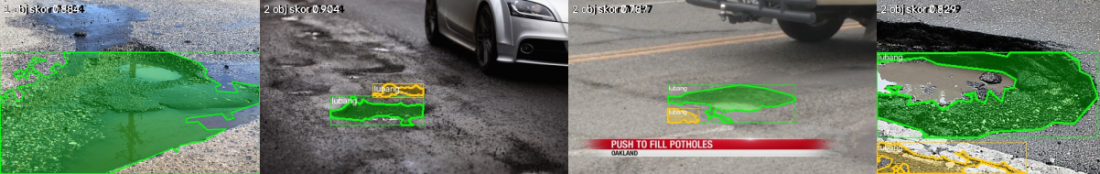

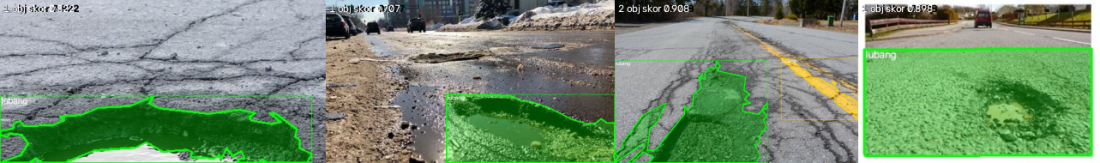


== orang: 123 gambar berlabel, tampil 8 ==


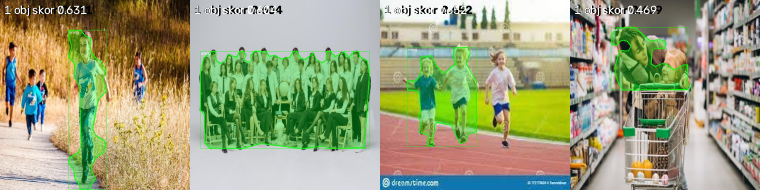

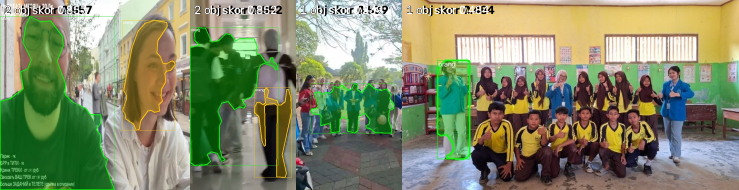


== motor: 220 gambar berlabel, tampil 8 ==


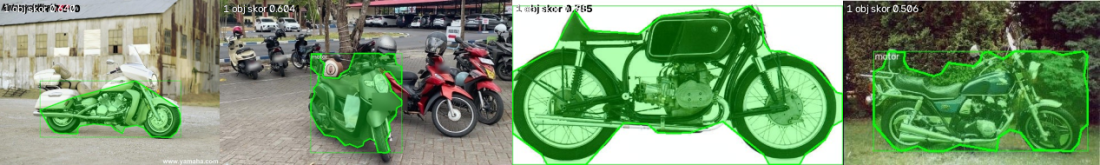

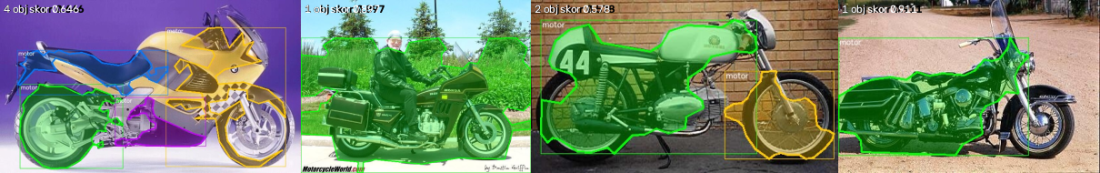


== mobil: 199 gambar berlabel, tampil 8 ==


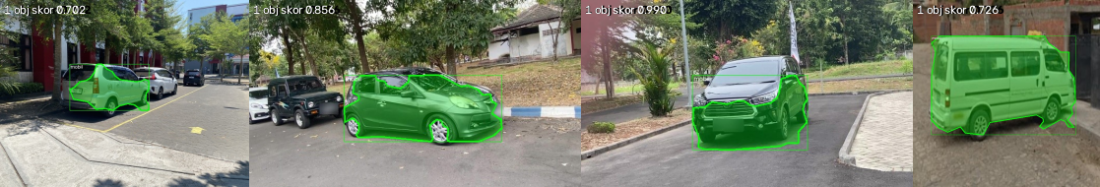

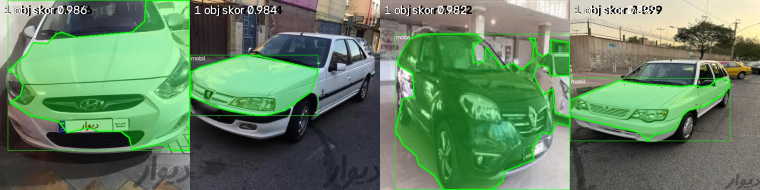

In [10]:
MAKS_GALERI = 8
for k in CLASSES:
    rr = [r for r in hasil if r["kelas"] == k]
    if not rr:
        continue
    pilih = rr[::max(1, len(rr) // MAKS_GALERI)][:MAKS_GALERI]
    print(f"\n== {k}: {len(rr)} gambar berlabel, tampil {len(pilih)} ==")
    tampil_baris([(baca_gambar(D_LABEL / "gambar_berlabel" / r["file"]), f"{r['n_objek']} obj skor {r['skor']}") for r in pilih])

## 11. Gambar yang dilewati

Gambar yang tidak dilabel karena status belum layak. Bila terlalu banyak, perbaiki lewat notebook 02b atau setel `ambang_cek`.

In [11]:
lewat = [r for r in laporan if r["status"] not in layak]
print("Dilewati total:", len(lewat))
for k in CLASSES:
    rr = sorted([r for r in lewat if r["kelas"] == k], key=lambda x: float(x["skor"]))[:MAKS_GALERI]
    if not rr:
        continue
    print(f"\n== {k}: {sum(r['kelas'] == k for r in lewat)} dilewati, tampil {len(rr)} skor terendah ==")
    tampil_baris([(baca_gambar(D_SEG / "overlay" / k / (r["file"].rsplit(".", 1)[0] + ".jpg")), f"{r['skor']} {r['status']}") for r in rr])
if not lewat:
    print("Tidak ada gambar yang dilewati.")

Dilewati total: 0
Tidak ada gambar yang dilewati.


## 12. Pemeriksaan akhir

In [12]:
n_img = len(list((D_LABEL / "images").glob("*.jpg"))) if (D_LABEL / "images").is_dir() else 0
n_seg = len(list((D_LABEL / "labels_seg").glob("*.txt"))) if (D_LABEL / "labels_seg").is_dir() else 0
n_det = len(list((D_LABEL / "labels_det").glob("*.txt"))) if (D_LABEL / "labels_det").is_dir() else 0
print(f"images={n_img}  labels_seg={n_seg}  labels_det={n_det}  (harus sama)")
log(TAHAP, f"selesai -> {D_LABEL}")
print("\nLanjut ke notebook 04_pengayaan.ipynb")

images=1046  labels_seg=1046  labels_det=1046  (harus sama)
[03_labelling] selesai -> C:\Projek\vestcare-dataset\hasil\03_labelling

Lanjut ke notebook 04_pengayaan.ipynb
